In [10]:
!pip install seaborn

  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)


In [6]:
from get_dataset import download_prepare_dataset, dataset
from sklearn.model_selection import train_test_split
import numpy as np
data_df = download_prepare_dataset()

In [7]:
data_df.head()

,text,category
0,أعلن المدرب النمسوي لبوروسيا دورتموند بيتر شتو...,Sports
1,ذكرت وسائل الإعلام البلغارية الجمعة ان العداءة...,Sports
2,برز اسم نجم مانشستر يونايتد رايان غيغز (36 عام...,Sports
3,قال مدرب نادي انتر ميلان الإيطالي خوزيه موريني...,Sports
4,بيتر تشيك: حارس مرمى تشيكي ولد في 20 مايو عام ...,Sports


In [8]:
X_train, X_test, y_train, y_test = train_test_split(np.array(data_df["text"]), np.array(data_df["category"]), test_size=0.3, stratify = data_df['category'].values)
X_val, X_test, y_val, y_test = train_test_split(X_test, y_test, test_size=0.5, stratify = y_test)
print("Training set is: ", X_train.shape[0], " rows which is ", round(X_train.shape[0]/data_df.shape[0],4)*100, "%")
print("Validation set is: ",X_val.shape[0], " rows which is ", round(X_val.shape[0]/data_df.shape[0],4)*100, "%")
print("Testing set is: ",X_test.shape[0], " rows which is ", round(X_test.shape[0]/data_df.shape[0],4)*100, "%")

Training set is:  31850  rows which is  70.0 %
Validation set is:  6825  rows which is  15.0 %
Testing set is:  6825  rows which is  15.0 %


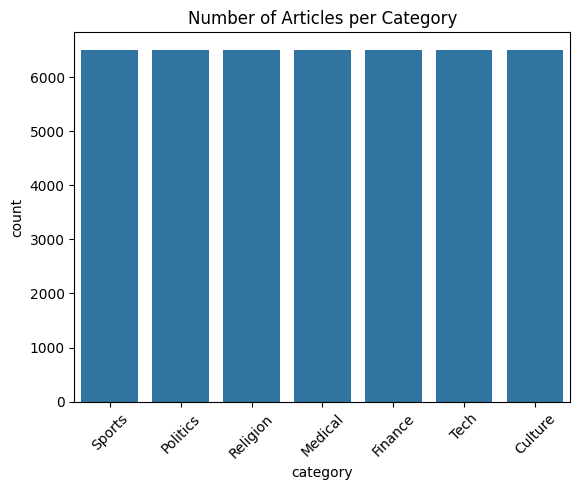

In [17]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(data=data_df, x='category')
plt.xticks(rotation=45)
plt.title("Number of Articles per Category")
plt.show()


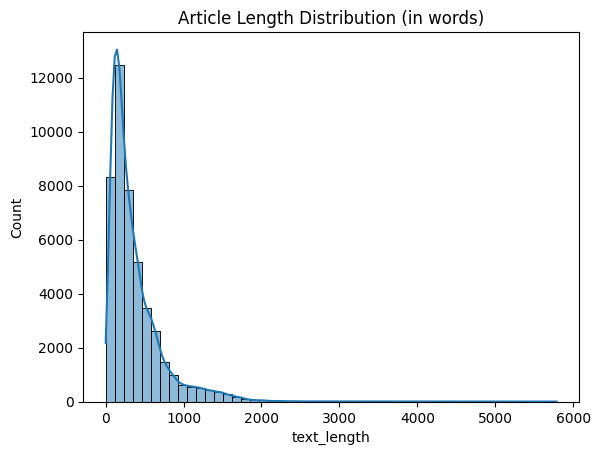

In [13]:
data_df['text_length'] = data_df['text'].apply(lambda x: len(x.split()))
sns.histplot(data_df['text_length'], bins=50, kde=True)
plt.title("Article Length Distribution (in words)")
plt.show()


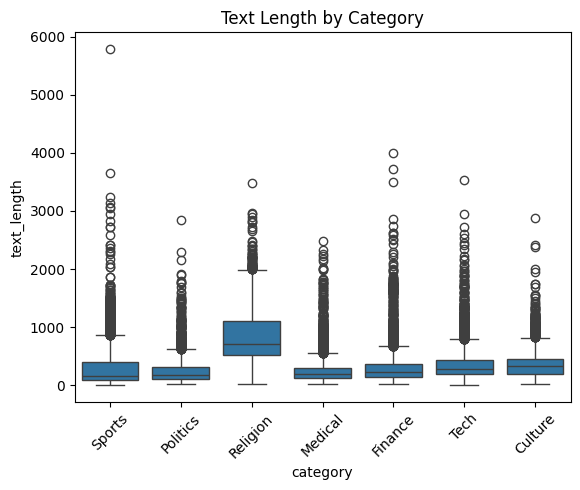

In [14]:
import pandas as pd
data_df['text_length'] = data_df['text'].apply(lambda x: len(x.split()))
sns.boxplot(data=data_df, x='category', y='text_length')
plt.xticks(rotation=45)
plt.title("Text Length by Category")
plt.show()


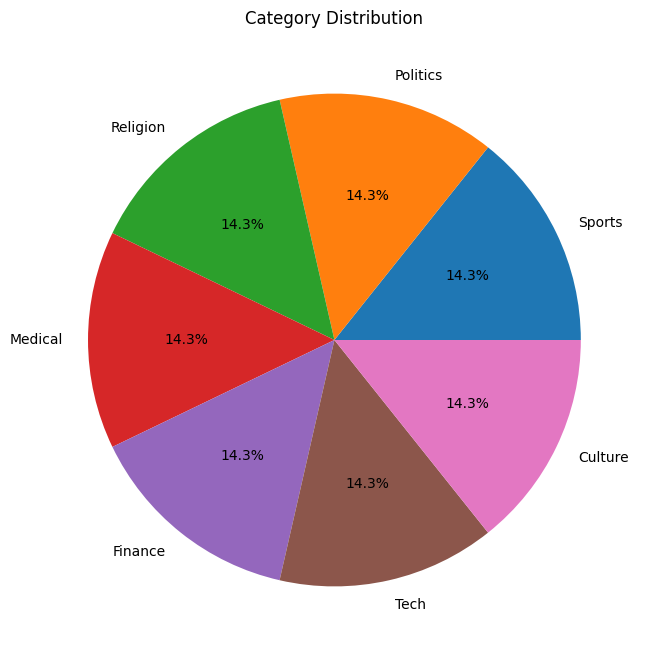

In [15]:
data_df['category'].value_counts().plot.pie(autopct='%1.1f%%', figsize=(8, 8))
plt.ylabel('')
plt.title("Category Distribution")
plt.show()
